<a href="https://colab.research.google.com/github/mohammadarifshaikh/Research-with-Data-Science/blob/main/Diabetes_prediction_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment

**Dataset:** [Diabetes Prediction Dataset – Kaggle](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset)

**Description:** The dataset contains ~100,000 patient records with 8 medical & demographic features and a binary target (`diabetes`: 0 or 1).

**Features:** `gender`, `age`, `hypertension`, `heart_disease`, `smoking_history`, `bmi`, `HbA1c_level`, `blood_glucose_level`

---

### Tasks:
1. Download the dataset from Kaggle and upload it to your Google Drive.
2. Load & preprocess the data (handle categoricals, scale features).
3. Train **SVM** and **Naive Bayes** classifiers.
4. Evaluate using **Precision, Recall, F1-Score, and ROC-AUC Curve**.
5. Create a **Results Summary Table** comparing both models.



Setup & Imports

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_curve, roc_auc_score)
import warnings
warnings.filterwarnings('ignore')

 Mount Drive & Load Dataset

In [5]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/datasets/diabetes_prediction_dataset.csv')
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


2. Load & preprocess the data (handle categoricals, scale features).

In [6]:


X = df.drop(columns=['diabetes'])
y = df['diabetes']


X = pd.get_dummies(X, drop_first=True)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Check result
print("Preprocessing completed.")
print(f"Train: {X_train.shape}")
print(f"Test : {X_test.shape}")

Preprocessing completed.
Train: (80000, 13)
Test : (20000, 13)


3. Train SVM and Naive Bayes classifiers.

In [7]:
# SVM (RBF kernel with probability estimates for ROC)
svm_model = SVC(kernel='rbf', probability=True, random_state=42)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

# Gaussian Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

print('Training complete.')

Training complete.


4. Evaluate using Precision, Recall, F1-Score, and ROC-AUC Curve.

In [8]:
print('='*55)
print('SVM Classification Report')
print('='*55)
print(classification_report(y_test, y_pred_svm, digits=4,
      target_names=['Non diabetes', 'diabetes']))

print('='*55)
print('Naive Bayes Classification Report')
print('='*55)
print(classification_report(y_test, y_pred_nb, digits=4,
      target_names=['Non diabetes', 'diabetes']))

SVM Classification Report
              precision    recall  f1-score   support

Non diabetes     0.9635    0.9980    0.9805     18300
    diabetes     0.9655    0.5929    0.7347      1700

    accuracy                         0.9636     20000
   macro avg     0.9645    0.7955    0.8576     20000
weighted avg     0.9637    0.9636    0.9596     20000

Naive Bayes Classification Report
              precision    recall  f1-score   support

Non diabetes     0.9989    0.1980    0.3305     18300
    diabetes     0.1036    0.9976    0.1877      1700

    accuracy                         0.2660     20000
   macro avg     0.5512    0.5978    0.2591     20000
weighted avg     0.9228    0.2660    0.3183     20000



ROC-AUC Curve

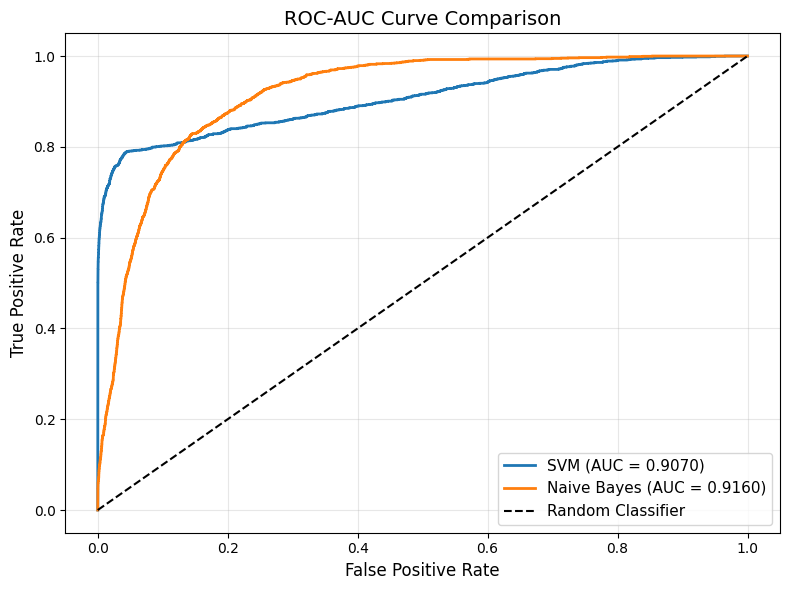

In [9]:
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
auc_svm = roc_auc_score(y_test, y_prob_svm)
auc_nb = roc_auc_score(y_test, y_prob_nb)

plt.figure(figsize=(8, 6))
plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc_svm:.4f})', linewidth=2)
plt.plot(fpr_nb, tpr_nb, label=f'Naive Bayes (AUC = {auc_nb:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC-AUC Curve Comparison', fontsize=14)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/datasets/roc_auc_curve.png', dpi=300)
plt.show()

5. Create a Results Summary Table comparing both models.

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

results = pd.DataFrame({
    'Model': ['SVM (RBF)', 'Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_nb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_nb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_nb)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_nb)
    ],
    'ROC-AUC': [auc_svm, auc_nb]
})

# Format to 4 decimal places
results.iloc[:, 1:] = results.iloc[:, 1:].round(4)
results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,SVM (RBF),0.9636,0.9655,0.5929,0.7347,0.907
1,Naive Bayes,0.2660,0.1036,0.9976,0.1877,0.916
